In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Localizar la raíz del repositorio
ubicacion = Path.cwd().resolve()

raices = [ubicacion, *ubicacion.parents]

raiz = next(
    (
        carpeta for carpeta in raices
        if (carpeta / "F2" / "data" / "processed").is_dir()
    ),
    None
)

assert raiz is not None, "No se encontró la raíz del proyecto"

# Cargar el dataset interpretable de F2
ruta_datos = (
    raiz / "F2" / "data" / "processed"
    / "licitaciones_filtradas_provisional.csv.gz"
)

df_visual = pd.read_csv(ruta_datos)

# Validaciones iniciales
columnas_necesarias = [
    "Estado",
    "EsDesierta",
    "sector",
    "RegionUnidad",
    "Tipo",
    "DiasPublicacionCierre",
    "MontoEstimadoNumerico",
    "Moneda Adquisicion"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df_visual.columns
]

assert not faltantes, f"Columnas no encontradas: {faltantes}"

print("Raíz del proyecto:", raiz)
print("Dimensiones:", df_visual.shape)
print("\nEstados:")
print(df_visual["Estado"].value_counts(dropna=False))

print("\nMonedas:")
print(df_visual["Moneda Adquisicion"].value_counts(dropna=False))

print("\nValores faltantes por variable:")
print(df_visual[columnas_necesarias].isna().sum())


Raíz del proyecto: C:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500
Dimensiones: (41607, 18)

Estados:
Estado
Adjudicada                            35622
Desierta (o art. 3 ó 9 Ley 19.886)     5985
Name: count, dtype: int64

Monedas:
Moneda Adquisicion
Peso Chileno         40786
Unidad de Fomento      500
Dolar                  298
Moneda revisar          22
Euro                     1
Name: count, dtype: int64

Valores faltantes por variable:
Estado                      0
EsDesierta                  0
sector                   1539
RegionUnidad                0
Tipo                        0
DiasPublicacionCierre       0
MontoEstimadoNumerico       7
Moneda Adquisicion          0
dtype: int64


In [2]:

# Carpeta de resultados de Fase 4
carpeta_resultados = raiz / "F4" / "resultados"
carpeta_resultados.mkdir(parents=True, exist_ok=True)

print("Carpeta de resultados:", carpeta_resultados)


Carpeta de resultados: C:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500\F4\resultados


## 1. Caracterización general de las licitaciones

Se analiza la distribución de las licitaciones adjudicadas y desiertas
correspondientes al primer semestre de 2026.

Esta visualización constituye el contexto inicial del análisis y permite
dimensionar el fenómeno antes de comparar sus características.

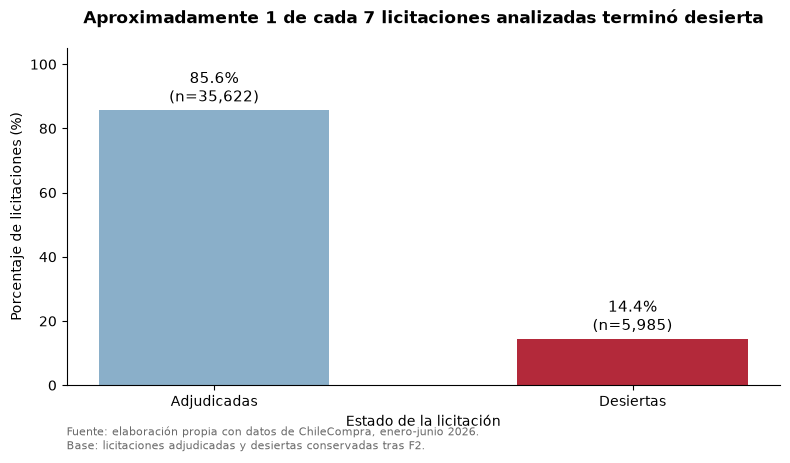

Total de licitaciones: 41607
Total adjudicadas: 35622
Total desiertas: 5985


In [3]:

# Gráfico 1: distribución porcentual por estado

# Validar que la variable objetivo contenga solo valores binarios
assert df_visual["EsDesierta"].notna().all()
assert set(df_visual["EsDesierta"].unique()) == {0, 1}

# Calcular cantidades y porcentajes
conteos = (
    df_visual["EsDesierta"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

porcentajes = conteos / len(df_visual) * 100

etiquetas = ["Adjudicadas", "Desiertas"]
colores = ["#8AAFC9", "#B3293A"]

fig, ax = plt.subplots(figsize=(8, 4.8))

barras = ax.bar(
    etiquetas,
    porcentajes.values,
    color=colores,
    width=0.55
)

# Mostrar porcentaje y cantidad exacta
for barra, porcentaje, cantidad in zip(
    barras, porcentajes.values, conteos.values
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1.2,
        f"{porcentaje:.1f}%\n(n={cantidad:,})",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title(
    "Aproximadamente 1 de cada 7 licitaciones analizadas terminó desierta",
    fontsize=12,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Porcentaje de licitaciones (%)")
ax.set_xlabel("Estado de la licitación")
ax.set_ylim(0, 105)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.text(
    0, -0.19,
    "Fuente: elaboración propia con datos de ChileCompra, enero-junio 2026.\n"
    "Base: licitaciones adjudicadas y desiertas conservadas tras F2.",
    transform=ax.transAxes,
    fontsize=8,
    color="dimgray"
)

fig.savefig(
    carpeta_resultados / "grafico_1_estados.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

print("Total de licitaciones:", len(df_visual))
print("Total adjudicadas:", conteos.loc[0])
print("Total desiertas:", conteos.loc[1])

assert conteos.sum() == len(df_visual)



### Interpretación del gráfico 1

**¿Qué muestra?**

De las 41.607 licitaciones conservadas después del
preprocesamiento de F2, 35.622 fueron adjudicadas (85,6 %)
y 5.985 fueron declaradas desiertas (14,4 %).

**¿Qué podemos inferir?**

La mayoría de las licitaciones analizadas fueron adjudicadas.
Sin embargo, aproximadamente una de cada siete terminó
desierta, lo que justifica examinar qué características
diferencian ambos grupos.

**¿Qué limitaciones tiene?**

Los porcentajes representan únicamente las licitaciones
incluidas en el conjunto analítico, correspondientes al
primer semestre de 2026 y a los estados seleccionados
en F2. No deben interpretarse como la tasa general de
licitaciones desiertas de todo el sistema de compras
públicas de Chile.

Además, el gráfico no permite identificar las causas
por las cuales una licitación terminó desierta.

**¿Cómo aporta al proyecto?**

Responde al objetivo específico de caracterizar las
licitaciones públicas del período estudiado y establece
el contexto para comparar sus características según
sector, tipo de licitación y plazos de publicación.


## 2. Comparación de licitaciones desiertas por tipo

Se analiza la proporción de licitaciones declaradas desiertas
según el tipo de procedimiento.

La comparación utiliza porcentajes dentro de cada tipo, ya
que las categorías pueden contener cantidades muy diferentes
de licitaciones.

In [4]:

# Gráfico 2: preparación de tasas por tipo de licitación

# Validar los datos de entrada
assert df_visual["Tipo"].notna().all()
assert df_visual["EsDesierta"].isin([0, 1]).all()

# Calcular cantidades y tasas por tipo
resumen_tipo = (
    df_visual
    .groupby("Tipo", dropna=False)
    .agg(
        Total=("EsDesierta", "size"),
        Desiertas=("EsDesierta", "sum")
    )
    .reset_index()
)

resumen_tipo["TasaDesierta"] = (
    resumen_tipo["Desiertas"]
    / resumen_tipo["Total"] * 100
)

resumen_tipo = resumen_tipo.sort_values(
    "TasaDesierta",
    ascending=False
).reset_index(drop=True)

# Validar coherencia del resumen
assert resumen_tipo["Total"].sum() == len(df_visual)
assert resumen_tipo["Desiertas"].sum() == df_visual["EsDesierta"].sum()
assert resumen_tipo["TasaDesierta"].between(0, 100).all()

print("Tasas de licitaciones desiertas por tipo:")
print(
    resumen_tipo.to_string(
        index=False,
        formatters={"TasaDesierta": "{:.2f}%".format}
    )
)

print("\nTipos con menos de 30 licitaciones:")
print(
    resumen_tipo.loc[
        resumen_tipo["Total"] < 30,
        ["Tipo", "Total", "Desiertas", "TasaDesierta"]
    ].to_string(index=False)
)


Tasas de licitaciones desiertas por tipo:
Tipo  Total  Desiertas TasaDesierta
  O2      2          1       50.00%
  E2     74         30       40.54%
  B2    222         72       32.43%
  CO    654        196       29.97%
  I2     42         12       28.57%
  O1    150         30       20.00%
  LQ      6          1       16.67%
  L1   4944        782       15.82%
  LR   1883        292       15.51%
  LE  25396       3559       14.01%
  LP   8218       1010       12.29%
  LS     16          0        0.00%

Tipos con menos de 30 licitaciones:
Tipo  Total  Desiertas  TasaDesierta
  O2      2          1     50.000000
  LQ      6          1     16.666667
  LS     16          0      0.000000


Tipos incluidos: 9
Tipos excluidos de la figura: ['O2', 'LQ', 'LS']
Licitaciones fuera de la figura: 24


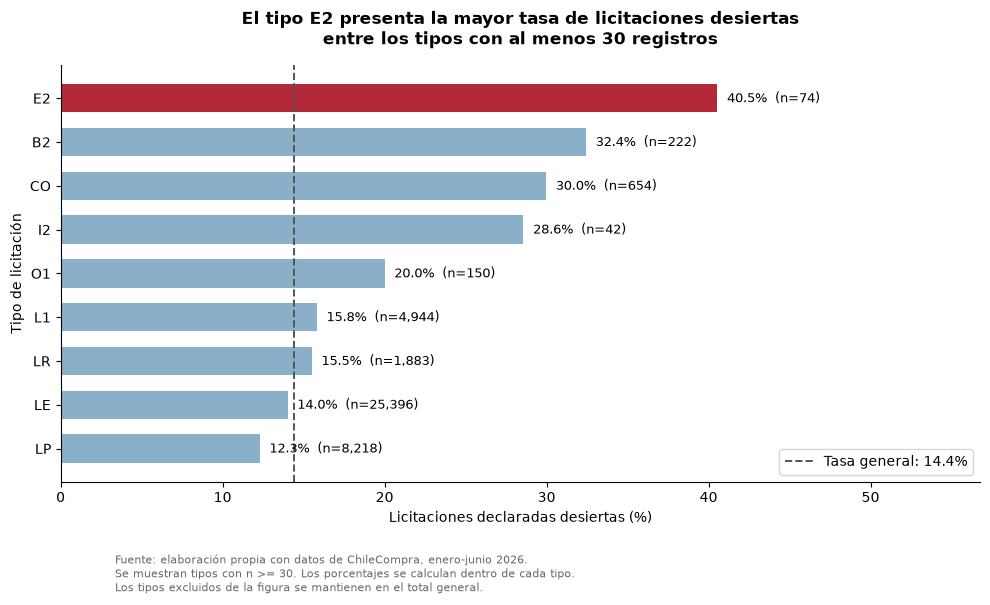

In [5]:

# Gráfico 2: tasa de licitaciones desiertas por tipo

# Umbral descriptivo para evitar destacar grupos muy pequeños
minimo_registros = 30

resumen_grafico = (
    resumen_tipo.loc[
        resumen_tipo["Total"] >= minimo_registros
    ]
    .sort_values("TasaDesierta", ascending=True)
    .copy()
)

# Verificar las categorías incluidas y excluidas
assert not resumen_grafico.empty
assert (resumen_grafico["Total"] >= minimo_registros).all()

excluidos = resumen_tipo.loc[
    resumen_tipo["Total"] < minimo_registros
]

print("Tipos incluidos:", len(resumen_grafico))
print("Tipos excluidos de la figura:", excluidos["Tipo"].tolist())
print("Licitaciones fuera de la figura:", excluidos["Total"].sum())

# Tasa general calculada usando todas las licitaciones
tasa_general = df_visual["EsDesierta"].mean() * 100

# Identificar la mayor tasa entre los tipos incluidos
mayor = resumen_grafico.loc[
    resumen_grafico["TasaDesierta"].idxmax()
]

colores = [
    "#B3293A" if tipo == mayor["Tipo"] else "#8AAFC9"
    for tipo in resumen_grafico["Tipo"]
]

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    resumen_grafico["Tipo"],
    resumen_grafico["TasaDesierta"],
    color=colores,
    height=0.65
)

# Porcentaje y cantidad de observaciones
for barra, fila in zip(barras, resumen_grafico.itertuples()):
    ax.text(
        barra.get_width() + 0.6,
        barra.get_y() + barra.get_height() / 2,
        f"{fila.TasaDesierta:.1f}%  (n={fila.Total:,})",
        va="center",
        fontsize=9
    )

# Comparación con la tasa general del conjunto
ax.axvline(
    tasa_general,
    color="#555555",
    linestyle="--",
    linewidth=1.4,
    label=f"Tasa general: {tasa_general:.1f}%"
)

ax.set_title(
    f"El tipo {mayor['Tipo']} presenta la mayor tasa "
    "de licitaciones desiertas\n"
    "entre los tipos con al menos 30 registros",
    fontsize=12,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Licitaciones declaradas desiertas (%)")
ax.set_ylabel("Tipo de licitación")
ax.set_xlim(0, resumen_grafico["TasaDesierta"].max() * 1.40)

ax.legend(loc="lower right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.12, 0.005,
    "Fuente: elaboración propia con datos de ChileCompra, enero-junio 2026.\n"
    "Se muestran tipos con n >= 30. Los porcentajes se calculan dentro de cada tipo.\n"
    "Los tipos excluidos de la figura se mantienen en el total general.",
    fontsize=8,
    color="dimgray"
)

fig.savefig(
    carpeta_resultados / "grafico_2_tipos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

# Comprobaciones finales
assert resumen_tipo["Total"].sum() == len(df_visual)
assert resumen_tipo["Desiertas"].sum() == df_visual["EsDesierta"].sum()



### Interpretación del gráfico 2

**¿Qué muestra?**

Se comparan las tasas de licitaciones desiertas según el
tipo de procedimiento. Entre las categorías con al menos
30 registros, E2 presenta la tasa más alta (40,54 %),
seguida de B2 (32,43 %) y CO (29,97 %).

En contraste, LP presenta una tasa de 12,29 %.

**¿Qué podemos inferir?**

Se observan diferencias en la proporción de licitaciones
desiertas entre los distintos tipos de procedimiento.

Estas diferencias justifican examinar el tipo de licitación
como una característica relevante del análisis.

**¿Qué limitaciones tiene?**

Los tipos de licitación tienen tamaños muy distintos.
Por ejemplo, E2 contiene 74 registros y LP contiene 8.218.

Se muestran únicamente categorías con al menos
30 registros. Este umbral es descriptivo y no garantiza
precisión estadística.

Las diferencias observadas no demuestran que el tipo
de licitación cause que un procedimiento termine desierto.

**¿Cómo aporta al proyecto?**

Responde al objetivo de comparar las características
de las licitaciones adjudicadas y desiertas.

Permite identificar tipos de licitación que merecen
un análisis más detallado antes de formular recomendaciones
para los organismos compradores.


## 3. Comparación de los plazos de publicación y cierre

Se analiza la duración entre la publicación y el cierre de las
licitaciones, comparando procedimientos adjudicados y desiertos.

Antes de visualizar los resultados, se revisa la distribución
de los plazos, los posibles valores inconsistentes y los
valores extremos para seleccionar una representación adecuada.

In [6]:

# Diagnóstico previo al gráfico 3

columna_plazo = "DiasPublicacionCierre"

# Preparar una copia sin modificar el dataset original
df_plazos = df_visual[
    ["Estado", "EsDesierta", columna_plazo]
].copy()

df_plazos[columna_plazo] = pd.to_numeric(
    df_plazos[columna_plazo],
    errors="coerce"
)

# Validar las categorías
assert df_plazos["EsDesierta"].isin([0, 1]).all()

# Revisar datos faltantes y posibles inconsistencias
print("Total de registros:", len(df_plazos))
print("Plazos faltantes:", df_plazos[columna_plazo].isna().sum())
print("Plazos negativos:", (df_plazos[columna_plazo] < 0).sum())
print("Plazos iguales a cero:", (df_plazos[columna_plazo] == 0).sum())

print("\nEstadísticas de días por estado:")

resumen_plazos = (
    df_plazos.groupby("Estado")[columna_plazo]
    .agg(
        Registros="count",
        Media="mean",
        Mediana="median",
        Minimo="min",
        Maximo="max"
    )
)

print(resumen_plazos.round(2).to_string())

print("\nPercentiles de los plazos:")

percentiles_plazos = (
    df_plazos.groupby("Estado")[columna_plazo]
    .quantile([0.25, 0.50, 0.75, 0.95, 0.99])
    .unstack()
)

print(percentiles_plazos.round(2).to_string())

# Diagnóstico adicional de valores elevados
print(
    "\nPlazos superiores a 90 días:",
    (df_plazos[columna_plazo] > 90).sum()
)


Total de registros: 41607
Plazos faltantes: 0
Plazos negativos: 0
Plazos iguales a cero: 0

Estadísticas de días por estado:
                                    Registros  Media  Mediana  Minimo  Maximo
Estado                                                                       
Adjudicada                              35622  13.98     12.0     5.0    84.0
Desierta (o art. 3 ó 9 Ley 19.886)       5985  14.60     12.0     5.0    82.0

Percentiles de los plazos:
                                    0.25  0.50  0.75  0.95  0.99
Estado                                                          
Adjudicada                          10.0  12.0  17.0  31.0  36.0
Desierta (o art. 3 ó 9 Ley 19.886)  10.0  12.0  18.0  32.0  42.0

Plazos superiores a 90 días: 0


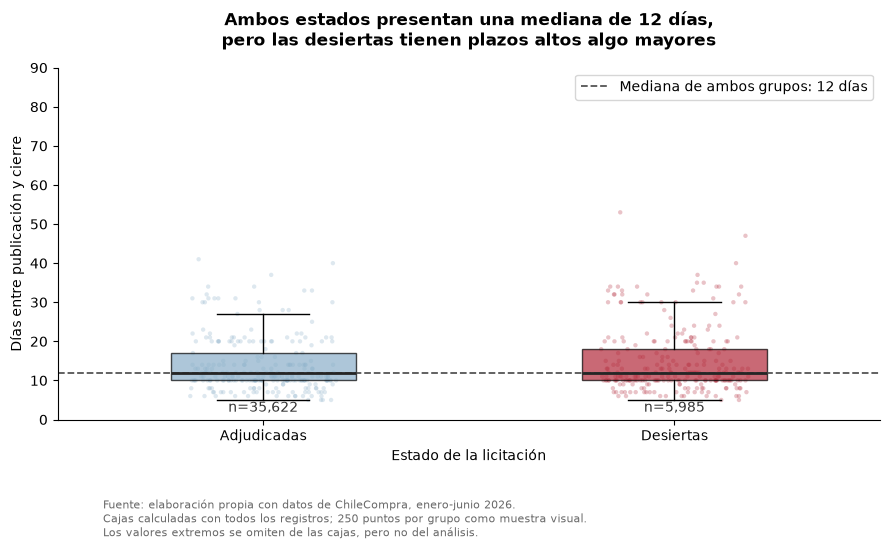

In [7]:

# Gráfico 3: distribución de plazos por estado
# Se utilizan todos los registros para calcular las cajas.
# Los puntos son una muestra visual reproducible.

datos_adjudicadas = df_plazos.loc[
    df_plazos["EsDesierta"] == 0,
    "DiasPublicacionCierre"
].dropna()

datos_desiertas = df_plazos.loc[
    df_plazos["EsDesierta"] == 1,
    "DiasPublicacionCierre"
].dropna()

assert len(datos_adjudicadas) == 35622
assert len(datos_desiertas) == 5985

grupos = [datos_adjudicadas, datos_desiertas]
etiquetas = ["Adjudicadas", "Desiertas"]
colores = ["#8AAFC9", "#B3293A"]

fig, ax = plt.subplots(figsize=(9, 5.5))

# Cajas calculadas utilizando todos los registros
cajas = ax.boxplot(
    grupos,
    tick_labels=etiquetas,
    patch_artist=True,
    widths=0.45,
    showfliers=False,
    medianprops={
        "color": "#252525",
        "linewidth": 2
    }
)

for caja, color in zip(cajas["boxes"], colores):
    caja.set_facecolor(color)
    caja.set_alpha(0.70)

# Muestra de puntos para visualizar observaciones reales
rng = np.random.default_rng(42)

for posicion, (datos, color) in enumerate(
    zip(grupos, colores), start=1
):
    muestra = datos.sample(
        n=min(250, len(datos)),
        random_state=42
    )

    desplazamiento = rng.uniform(
        -0.18, 0.18, len(muestra)
    )

    ax.scatter(
        np.full(len(muestra), posicion) + desplazamiento,
        muestra,
        s=10,
        color=color,
        alpha=0.28,
        edgecolors="none"
    )

# Línea de referencia: ambas medianas son 12 días
ax.axhline(
    12,
    linestyle="--",
    linewidth=1.3,
    color="#555555",
    label="Mediana de ambos grupos: 12 días"
)

ax.set_title(
    "Ambos estados presentan una mediana de 12 días,\n"
    "pero las desiertas tienen plazos altos algo mayores",
    fontsize=12,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Estado de la licitación")
ax.set_ylabel("Días entre publicación y cierre")
ax.set_ylim(0, 90)

ax.legend(loc="upper right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Tamaños reales por grupo
for posicion, datos in enumerate(grupos, start=1):
    ax.text(
        posicion,
        2,
        f"n={len(datos):,}",
        ha="center",
        fontsize=10,
        color="#333333"
    )

fig.text(
    0.12, 0.015,
    "Fuente: elaboración propia con datos de ChileCompra, enero-junio 2026.\n"
    "Cajas calculadas con todos los registros; "
    "250 puntos por grupo como muestra visual.\n"
    "Los valores extremos se omiten de las cajas, "
    "pero no del análisis.",
    fontsize=8,
    color="dimgray"
)

fig.savefig(
    carpeta_resultados / "grafico_3_plazos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

# Validaciones finales
assert datos_adjudicadas.median() == 12
assert datos_desiertas.median() == 12
assert len(datos_adjudicadas) + len(datos_desiertas) == len(df_plazos)



### Interpretación del gráfico 3

**¿Qué muestra?**

Se compara la distribución de los días entre publicación
y cierre de las licitaciones adjudicadas y desiertas.

Ambos grupos presentan una mediana de 12 días.
Las licitaciones adjudicadas registran una media de
13,98 días y las desiertas de 14,60 días.

El percentil 99 alcanza 36 días en las adjudicadas
y 42 días en las desiertas.

**¿Qué podemos inferir?**

No se observa una diferencia en el plazo mediano entre
ambos grupos. Sin embargo, las licitaciones desiertas
presentan valores ligeramente mayores en los percentiles
altos de la distribución.

Por lo tanto, el plazo puede ser una característica
de interés para análisis más detallados, pero las
diferencias descriptivas son limitadas.

**¿Qué limitaciones tiene?**

El gráfico representa asociaciones descriptivas y no
permite establecer causalidad.

Los resultados no controlan diferencias por tipo de
licitación, sector o institución compradora.

Las cajas se calcularon con todos los registros, mientras
que los puntos muestran una muestra reproducible de
250 observaciones por grupo.

**¿Cómo aporta al proyecto?**

Permite comparar una característica temporal de las
licitaciones adjudicadas y desiertas, contribuyendo
al objetivo de identificar patrones asociados al resultado
del procedimiento.


In [8]:

# Verificar las tres figuras exportadas
archivos_figuras = [
    "grafico_1_estados.png",
    "grafico_2_tipos.png",
    "grafico_3_plazos.png"
]

for nombre in archivos_figuras:
    ruta = carpeta_resultados / nombre
    assert ruta.is_file(), f"No se encontró: {nombre}"
    assert ruta.stat().st_size > 0, f"Archivo vacío: {nombre}"

    print(
        f"OK: {nombre} "
        f"({ruta.stat().st_size / 1024:.1f} KB)"
    )

print("\nLas tres figuras fueron exportadas correctamente.")


OK: grafico_1_estados.png (116.6 KB)
OK: grafico_2_tipos.png (199.9 KB)
OK: grafico_3_plazos.png (239.2 KB)

Las tres figuras fueron exportadas correctamente.


## 4. Tasas de deserción por sector y región

Se calculan las tasas de licitaciones desiertas por sector y región, utilizando intervalos de confianza de Wilson al 95%.Los valores faltantes de sector y región se conservan bajo la categoría No informado.

In [9]:
from pathlib import Path
import sys

print("Carpeta actual:", Path.cwd())
print("Raíz del proyecto:", raiz)
print("Python del notebook:", sys.executable)

print(
    "¿Existe analisis_f4.py?",
    (raiz / "src" / "analisis_f4.py").is_file()
)

print("Rutas de importación:", sys.path[:4])

Carpeta actual: c:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500\F4
Raíz del proyecto: C:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500
Python del notebook: c:\Users\Sergio\miniconda3\envs\MCDI500\python.exe
¿Existe analisis_f4.py? True
Rutas de importación: ['c:\\Users\\Sergio\\miniconda3\\envs\\MCDI500\\python313.zip', 'c:\\Users\\Sergio\\miniconda3\\envs\\MCDI500\\DLLs', 'c:\\Users\\Sergio\\miniconda3\\envs\\MCDI500\\Lib', 'c:\\Users\\Sergio\\miniconda3\\envs\\MCDI500']


In [10]:
from src.analisis_f4 import tasa_desercion_por_grupo

# Crear una copia para el análisis
df_tasas = df_visual.copy()

# Conservar las categorías sin información
for columna in ["sector", "RegionUnidad"]:
    df_tasas[columna] = (
        df_tasas[columna]
        .astype("string")
        .fillna("No informado")
        .str.strip()
        .replace("", "No informado")
    )

# Calcular tasas e intervalos por sector y región
for columna in ["sector", "RegionUnidad"]:

    resumen = tasa_desercion_por_grupo(
        df_tasas,
        columna_grupo=columna,
        min_casos_estables=30
    )

    # Comprobar que no se pierdan licitaciones
    assert resumen["total_n"].sum() == 41607
    assert resumen["desiertas_casos"].sum() == 5985

    # Expresar las tasas e intervalos en porcentajes
    resumen["Tasa_%"] = (
        resumen["tasa_desierta"] * 100
    ).round(2)

    resumen["IC_Inferior_%"] = (
        resumen["ic_inferior"] * 100
    ).round(2)

    resumen["IC_Superior_%"] = (
        resumen["ic_superior"] * 100
    ).round(2)

    print("\nResultados por:", columna)
    print("Total de licitaciones:", resumen["total_n"].sum())
    print("Total desiertas:", resumen["desiertas_casos"].sum())
    print("Grupos con baja frecuencia:",
          resumen["baja_frecuencia"].sum())

    display(resumen[
        [
            columna,
            "total_n",
            "desiertas_casos",
            "Tasa_%",
            "IC_Inferior_%",
            "IC_Superior_%",
            "baja_frecuencia"
        ]
    ])


Resultados por: sector
Total de licitaciones: 41607
Total desiertas: 5985
Grupos con baja frecuencia: 0


,sector,total_n,desiertas_casos,Tasa_%,IC_Inferior_%,IC_Superior_%,baja_frecuencia
0,Legislativo y judicial,297,66,22.22,17.87,27.29,False
1,Municipalidades,17376,2909,16.74,16.19,17.30,False
2,Otros,1110,168,15.14,13.15,17.36,False
3,No informado,1539,214,13.91,12.27,15.72,False
4,FFAA,3605,460,12.76,11.71,13.89,False
5,"Gob. Central, Universidades",5851,743,12.70,11.87,13.58,False
6,Obras Públicas,1464,183,12.50,10.90,14.29,False
7,Salud,10365,1242,11.98,11.37,12.62,False



Resultados por: RegionUnidad
Total de licitaciones: 41607
Total desiertas: 5985
Grupos con baja frecuencia: 0


,RegionUnidad,total_n,desiertas_casos,Tasa_%,IC_Inferior_%,IC_Superior_%,baja_frecuencia
0,Región de Tarapacá,804,179,22.26,19.52,25.27,False
1,Región de Atacama,1012,178,17.59,15.37,20.06,False
2,Región de Los Ríos,1237,205,16.57,14.60,18.75,False
3,Región Aysén del General Carlos Ibáñez del Campo,959,153,15.95,13.77,18.41,False
4,Región de Coquimbo,1768,279,15.78,14.16,17.55,False
5,Región del Ñuble,1390,219,15.76,13.93,17.76,False
6,Región de Valparaíso,3844,585,15.22,14.12,16.39,False
7,Región de los Lagos,2506,365,14.57,13.24,16.00,False
8,Región Metropolitana de Santiago,11990,1711,14.27,13.66,14.91,False
9,Región de la Araucanía,3137,441,14.06,12.89,15.32,False


En los datos analizado, el sector legislativo y judicial presenta la mayor tasa con un 22,22 %, seguido de municipalidades con 16,74 %). Por otro lado, salud presenta la menor tasa con un 11,98 %. Sin embargo, hay una diferencia importante en la precisión ya que legislativo y judicial sólo tienme 297 licitaciones, mientras municipalidades tiene 17.376, por eso el intervalo de confianza de legislativo es mucho más amplio.

Tasa global: 14.38%
Gráfico sector: C:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500\F4\resultados\grafico_4_tasa_sector_wilson.png
Gráfico región: C:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500\F4\resultados\grafico_5_tasa_region_wilson.png


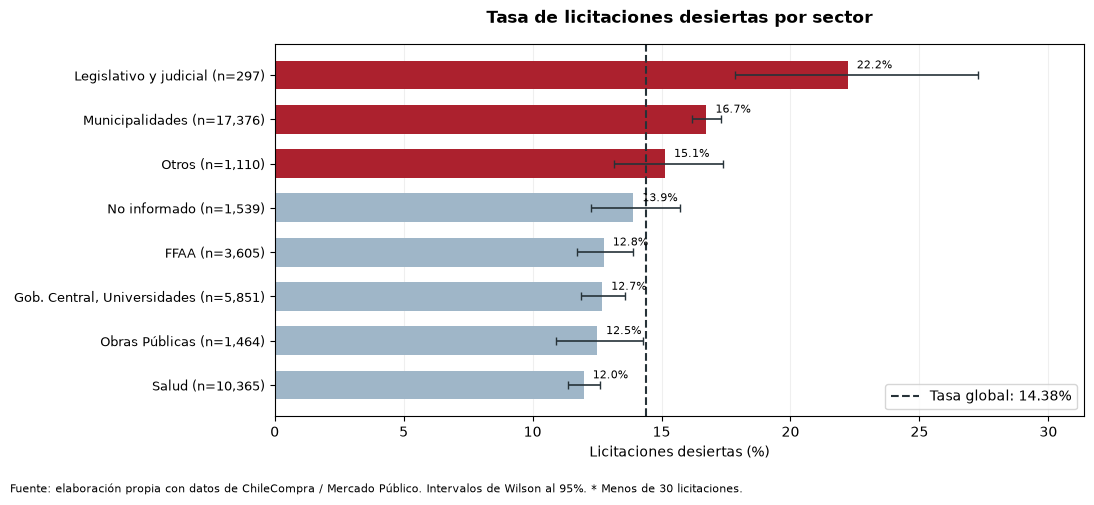

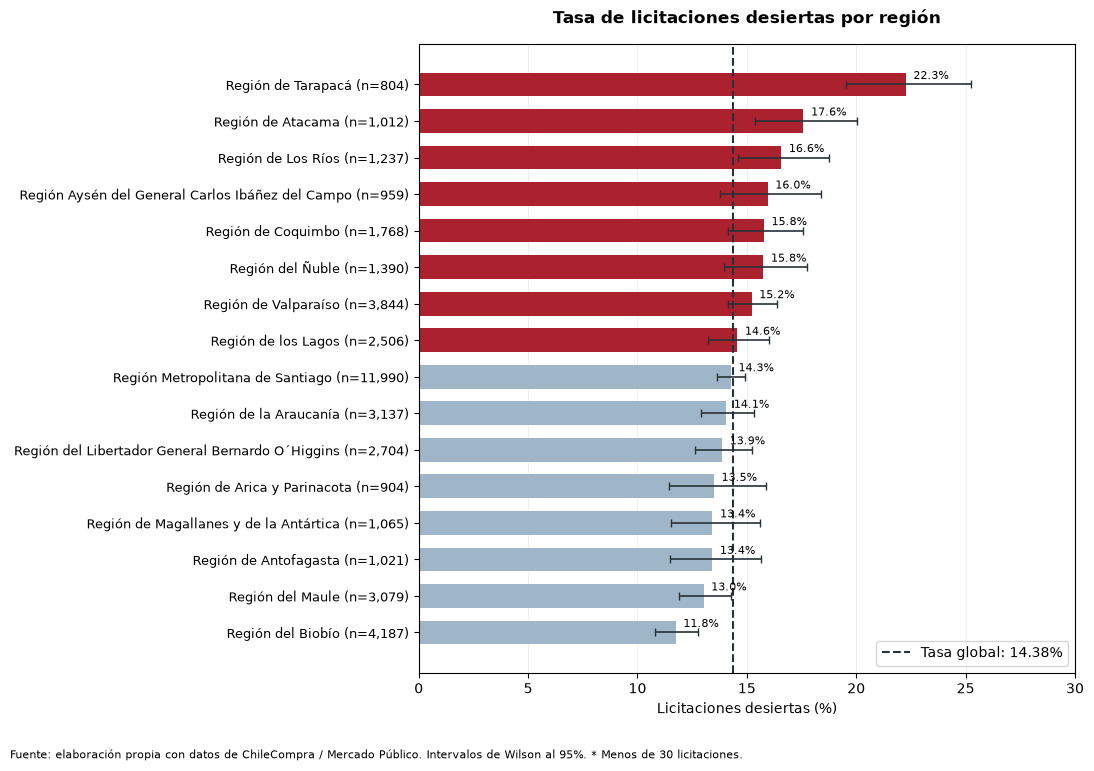

In [11]:
from src.analisis_f4 import (
    tasa_desercion_por_grupo,
    guardar_figura
)
from src.visualizaciones_f4 import graficar_tasas_por_grupo
import matplotlib.pyplot as plt

# Tasa global calculada a partir de los datos
tasa_global = df_tasas["EsDesierta"].mean()

# Resúmenes por sector y región
resumen_sector = tasa_desercion_por_grupo(
    df_tasas,
    columna_grupo="sector",
    min_casos_estables=30
)

resumen_region = tasa_desercion_por_grupo(
    df_tasas,
    columna_grupo="RegionUnidad",
    min_casos_estables=30
)

# Gráfico por sector
fig_sector = graficar_tasas_por_grupo(
    resumen_sector,
    columna="sector",
    titulo="Tasa de licitaciones desiertas por sector",
    tasa_global=tasa_global
)

# Gráfico por región
fig_region = graficar_tasas_por_grupo(
    resumen_region,
    columna="RegionUnidad",
    titulo="Tasa de licitaciones desiertas por región",
    tasa_global=tasa_global
)

# Guardar los resultados en F4
carpeta_resultados = raiz / "F4" / "resultados"

ruta_sector = guardar_figura(
    fig_sector,
    carpeta_resultados,
    "grafico_4_tasa_sector_wilson"
)

ruta_region = guardar_figura(
    fig_region,
    carpeta_resultados,
    "grafico_5_tasa_region_wilson"
)

print(f"Tasa global: {tasa_global * 100:.2f}%")
print("Gráfico sector:", ruta_sector)
print("Gráfico región:", ruta_region)

plt.show()

## 5. Comparación de montos estimados según el estado

Se comparan los montos estimados de las licitaciones adjudicadas y desiertas mediante la mediana y el rango intercuartílico.Para asegurar que sea comparable el analísus se limita a las licitaciones expresadas en pesos chilenos.

In [12]:
from src.analisis_f4 import resumen_montos_y_plazos

# Trabajar sobre una copia de los datos de F2
# y conservar únicamente los montos expresados en CLP
df_montos_clp = df_visual.loc[
    df_visual["Moneda Adquisicion"] == "Peso Chileno"
].copy()

# Asegurar que los montos sean numéricos
df_montos_clp["MontoEstimadoNumerico"] = pd.to_numeric(
    df_montos_clp["MontoEstimadoNumerico"],
    errors="coerce"
)

# Diagnóstico de los montos disponibles
print("Total de licitaciones:", len(df_visual))
print("Licitaciones en CLP:", len(df_montos_clp))
print("Licitaciones en otras monedas:",
      len(df_visual) - len(df_montos_clp))

print("\nMontos faltantes:",
      df_montos_clp["MontoEstimadoNumerico"].isna().sum())

print("Montos iguales o menores que cero:",
      (df_montos_clp["MontoEstimadoNumerico"] <= 0).sum())

# Para la futura escala logarítmica se requieren montos positivos
df_montos_validos = df_montos_clp.loc[
    df_montos_clp["MontoEstimadoNumerico"].notna()
    & (df_montos_clp["MontoEstimadoNumerico"] > 0)
].copy()

# Comprobar que se mantienen estados válidos
assert df_montos_validos["EsDesierta"].isin([0, 1]).all()

print("\nRegistros válidos para comparar montos:",
      len(df_montos_validos))

print("\nRegistros válidos por estado:")
print(df_montos_validos["EsDesierta"].value_counts())

# Reutilizar la función desarrollada en F4
resumen_montos = resumen_montos_y_plazos(
    df_montos_validos
)

print("\nResumen de montos estimados en CLP:")
display(
    resumen_montos[
        [
            "Estado",
            "Total_n",
            "Monto_Mediana_CLP",
            "Monto_IQR_CLP"
        ]
    ].round(2)
)

Total de licitaciones: 41607
Licitaciones en CLP: 40786
Licitaciones en otras monedas: 821

Montos faltantes: 7
Montos iguales o menores que cero: 0

Registros válidos para comparar montos: 40779

Registros válidos por estado:
EsDesierta
0    34956
1     5823
Name: count, dtype: int64

Resumen de montos estimados en CLP:


,Estado,Total_n,Monto_Mediana_CLP,Monto_IQR_CLP
0,Adjudicada,34956,28200000.0,58566418.25
1,Desierta,5823,24500000.0,59000000.00


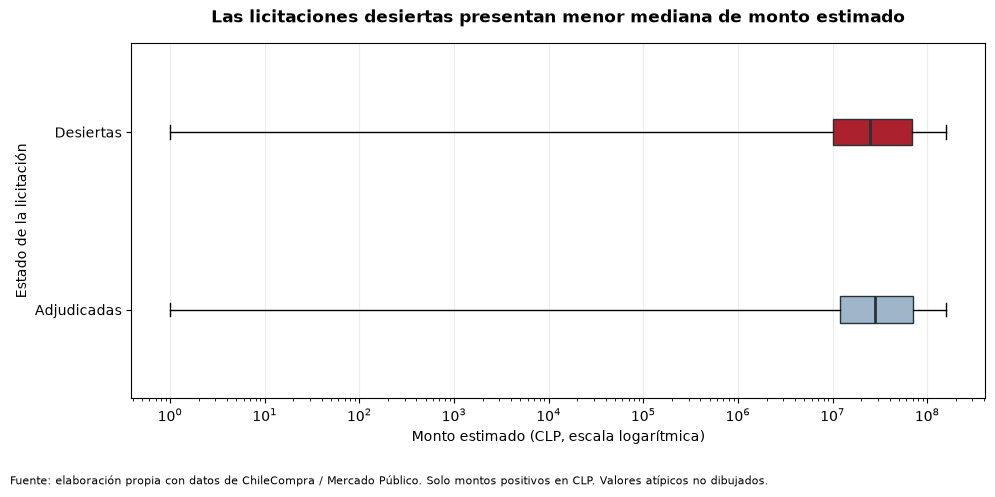

Gráfico guardado en: C:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500\F4\resultados\grafico_6_montos_por_estado.png


In [13]:
from src.analisis_f4 import guardar_figura
from src.visualizaciones_f4 import graficar_montos_por_estado
import matplotlib.pyplot as plt

# Crear el gráfico con los montos válidos en CLP
fig_montos = graficar_montos_por_estado(df_montos_validos)

# Mostrar el gráfico
display(fig_montos)

# Guardarlo en F4/resultados
ruta_montos = guardar_figura(
    fig_montos,
    raiz / "F4" / "resultados",
    "grafico_6_montos_por_estado"
)

print("Gráfico guardado en:", ruta_montos)

plt.close(fig_montos)

La mediana del monto estimado de las licitaciones adjudicadas es de 28,2 MM, mientras que las desiertas es de $ 24,5 MM, es decir, que las desiertas tienen un monto estimado menor de un 13,1% menor.

## 6. Comparación de montos según tipo de licitación

Se comparan las medianas de los montos estimados de las licitaciones adjudicadas y desiertas dentro de cada tipo de licitación.

In [14]:
# Comparación de montos dentro de cada tipo de licitación

resumen_tipo_monto = (
    df_montos_validos
    .groupby(["Tipo", "EsDesierta"], observed=True)
    .agg(
        Total_n=("MontoEstimadoNumerico", "size"),
        Mediana_CLP=("MontoEstimadoNumerico", "median"),
        Q1_CLP=("MontoEstimadoNumerico",
                lambda x: x.quantile(0.25)),
        Q3_CLP=("MontoEstimadoNumerico",
                lambda x: x.quantile(0.75))
    )
    .reset_index()
)

# Identificar el estado de la licitación
resumen_tipo_monto["Estado"] = (
    resumen_tipo_monto["EsDesierta"]
    .map({0: "Adjudicada", 1: "Desierta"})
)

# Calcular rango intercuartílico
resumen_tipo_monto["IQR_CLP"] = (
    resumen_tipo_monto["Q3_CLP"]
    - resumen_tipo_monto["Q1_CLP"]
)

# Marcar grupos con menos de 30 licitaciones
resumen_tipo_monto["Baja_frecuencia"] = (
    resumen_tipo_monto["Total_n"] < 30
)

# Ordenar para facilitar la comparación
resumen_tipo_monto = resumen_tipo_monto.sort_values(
    ["Tipo", "EsDesierta"]
)

# Mostrar tabla de resultados
display(
    resumen_tipo_monto[
        [
            "Tipo",
            "Estado",
            "Total_n",
            "Mediana_CLP",
            "IQR_CLP",
            "Baja_frecuencia"
        ]
    ].round(2)
)

,Tipo,Estado,Total_n,Mediana_CLP,IQR_CLP,Baja_frecuencia
0,B2,Adjudicada,143,134800000.0,9.886723e+07,False
1,B2,Desierta,71,123500000.0,1.104297e+08,False
2,CO,Adjudicada,450,21204201.5,2.714570e+07,False
3,CO,Desierta,191,25750000.0,3.298505e+07,False
4,E2,Adjudicada,44,4161635.0,3.566603e+06,False
5,E2,Desierta,30,3959000.0,3.450000e+06,False
6,I2,Adjudicada,28,607950543.5,2.806427e+08,True
7,I2,Desierta,10,564000000.0,4.178099e+08,True
8,L1,Adjudicada,4136,4600000.0,3.699118e+06,False
9,L1,Desierta,777,3800000.0,4.000000e+06,False


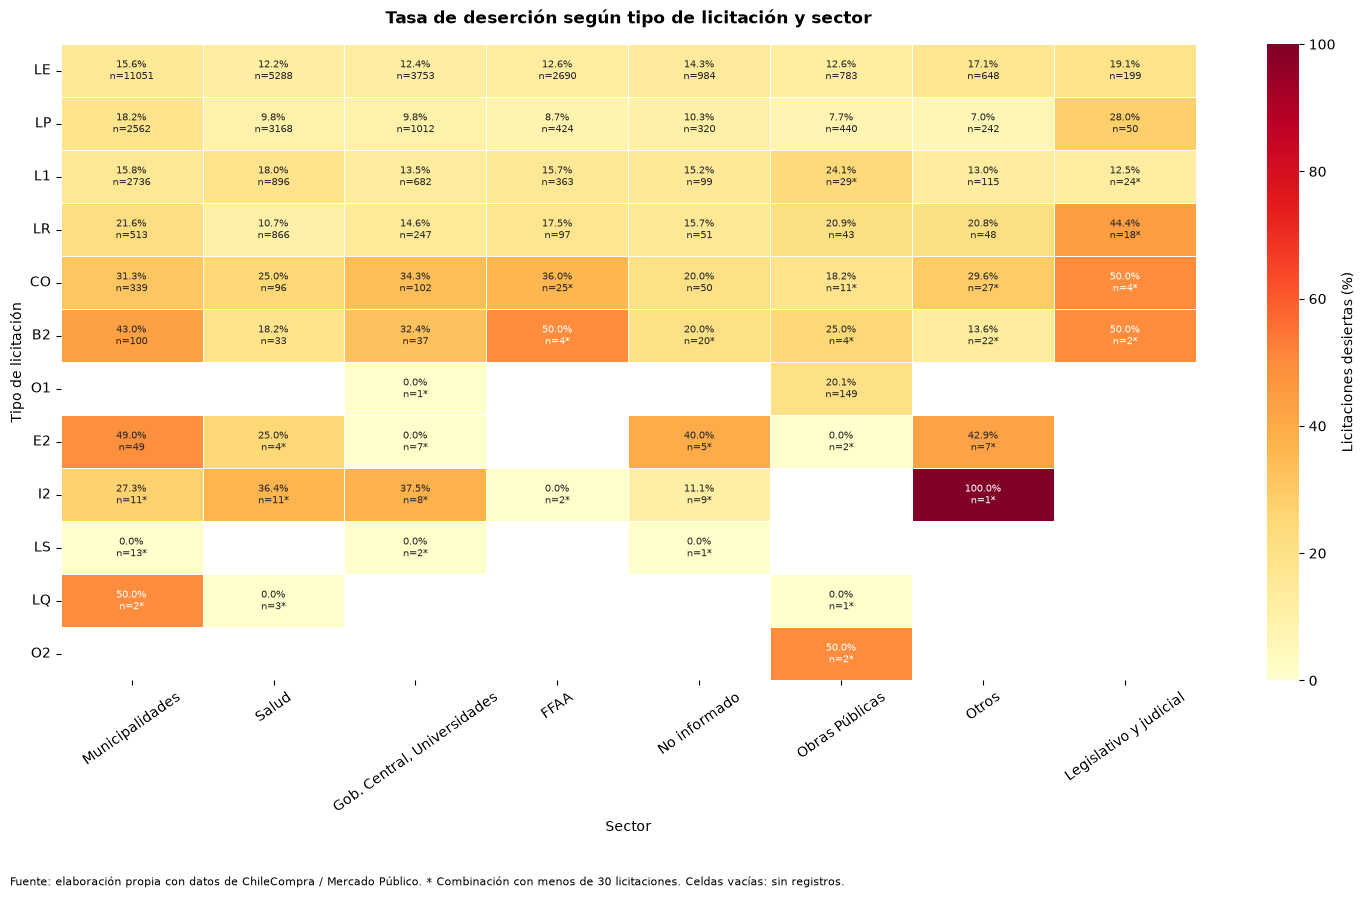

Mapa de calor guardado en: C:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500\F4\resultados\grafico_7_mapa_calor_tipo_sector.png


In [15]:

import importlib
import src.visualizaciones_f4 as vis
from src.analisis_f4 import guardar_figura
import matplotlib.pyplot as plt

# Recargar el módulo para incorporar la nueva función
importlib.reload(vis)

# Crear el mapa de calor utilizando las 41.607 licitaciones
fig_mapa = vis.graficar_mapa_tipo_sector(
    df_tasas,
    min_casos=30
)

# Mostrar el gráfico en JupyterLab
display(fig_mapa)

# Guardar el gráfico en F4/resultados
ruta_mapa = guardar_figura(
    fig_mapa,
    raiz / "F4" / "resultados",
    "grafico_7_mapa_calor_tipo_sector"
)

print("Mapa de calor guardado en:", ruta_mapa)

plt.close(fig_mapa)

Estos resultados muestran que las diferencias entre sectores también aparecen al comparar licitaciones del mismo tipo

## 7. Tasas de deserción según rangos de monto

Se analizan las tasas de licitaciones desiertas según cuatro rangos de monto estimado que definimos mediante cuartiles, el análisis considera exclusivamente licitaciones con montos expresados en pesos chilenos.

In [16]:
from src.analisis_f4 import tasa_desercion_por_grupo

# Utilizar los registros con montos válidos en CLP
df_rangos = df_montos_validos.copy()

# Crear cuatro rangos de monto mediante cuartiles
df_rangos["RangoMontoCLP"] = pd.qcut(
    df_rangos["MontoEstimadoNumerico"],
    q=4,
    duplicates="drop"
)

# Calcular tasas e intervalos de Wilson
resumen_rangos = tasa_desercion_por_grupo(
    df_rangos,
    columna_grupo="RangoMontoCLP",
    min_casos_estables=30
)

# Comprobar que no se pierdan registros
assert resumen_rangos["total_n"].sum() == 40779
assert resumen_rangos["desiertas_casos"].sum() == 5823

# Ordenar los rangos desde el monto menor al mayor
resumen_rangos = resumen_rangos.sort_values(
    "RangoMontoCLP"
).copy()

# Convertir tasas e intervalos a porcentajes
resumen_rangos["Tasa_%"] = (
    resumen_rangos["tasa_desierta"] * 100
).round(2)

resumen_rangos["IC_Inferior_%"] = (
    resumen_rangos["ic_inferior"] * 100
).round(2)

resumen_rangos["IC_Superior_%"] = (
    resumen_rangos["ic_superior"] * 100
).round(2)

print("Total de licitaciones:", resumen_rangos["total_n"].sum())
print("Total desiertas:", resumen_rangos["desiertas_casos"].sum())

display(
    resumen_rangos[
        [
            "RangoMontoCLP",
            "total_n",
            "desiertas_casos",
            "Tasa_%",
            "IC_Inferior_%",
            "IC_Superior_%",
            "baja_frecuencia"
        ]
    ]
)

Total de licitaciones: 40779
Total desiertas: 5823


,RangoMontoCLP,total_n,desiertas_casos,Tasa_%,IC_Inferior_%,IC_Superior_%,baja_frecuencia
0,"(0.999, 11434710.0]",10195,1635,16.04,15.34,16.76,False
1,"(11434710.0, 27600000.0]",10198,1469,14.40,13.74,15.10,False
2,"(27600000.0, 70000000.0]",10313,1398,13.56,12.91,14.23,False
3,"(70000000.0, 660450000000.0]",10073,1321,13.11,12.47,13.79,False


In [17]:
from src.analisis_f4 import tasa_desercion_por_grupo
import pandas as pd

# Tipos con cantidades suficientes para el análisis
tipos_principales = ["L1", "LE", "LP", "LR", "CO"]

resultados_por_tipo = []

for tipo in tipos_principales:

    # Seleccionar licitaciones del mismo tipo
    datos_tipo = df_montos_validos.loc[
        df_montos_validos["Tipo"] == tipo
    ].copy()

    # Cuartiles calculados dentro del tipo
    datos_tipo["CuartilMonto"] = pd.qcut(
        datos_tipo["MontoEstimadoNumerico"],
        q=4,
        labels=False,
        duplicates="drop"
    )

    # Utilizar la función desarrollada por Mario
    resumen = tasa_desercion_por_grupo(
        datos_tipo,
        columna_grupo="CuartilMonto",
        min_casos_estables=30
    )

    resumen["Tipo"] = tipo
    resumen["Cuartil"] = (
        "Q" + (resumen["CuartilMonto"] + 1).astype(str)
    )

    resultados_por_tipo.append(resumen)

# Unir resultados
comparacion_tipos = pd.concat(
    resultados_por_tipo,
    ignore_index=True
)

# Convertir tasas e intervalos a porcentaje
comparacion_tipos["Tasa_%"] = (
    comparacion_tipos["tasa_desierta"] * 100
).round(2)

comparacion_tipos["IC_Inferior_%"] = (
    comparacion_tipos["ic_inferior"] * 100
).round(2)

comparacion_tipos["IC_Superior_%"] = (
    comparacion_tipos["ic_superior"] * 100
).round(2)

comparacion_tipos = comparacion_tipos.sort_values(
    ["Tipo", "CuartilMonto"]
)

display(
    comparacion_tipos[
        [
            "Tipo",
            "Cuartil",
            "total_n",
            "desiertas_casos",
            "Tasa_%",
            "IC_Inferior_%",
            "IC_Superior_%",
            "baja_frecuencia"
        ]
    ]
)

,Tipo,Cuartil,total_n,desiertas_casos,Tasa_%,IC_Inferior_%,IC_Superior_%,baja_frecuencia
19,CO,Q1,161,41,25.47,19.36,32.71,False
17,CO,Q2,162,47,29.01,22.57,36.42,False
18,CO,Q3,161,46,28.57,22.16,35.99,False
16,CO,Q4,157,57,36.31,29.19,44.07,False
0,L1,Q1,1255,268,21.35,19.18,23.71,False
2,L1,Q2,1239,185,14.93,13.06,17.02,False
1,L1,Q3,1191,184,15.45,13.51,17.61,False
3,L1,Q4,1228,140,11.40,9.74,13.30,False
4,LE,Q1,6233,936,15.02,14.15,15.93,False
5,LE,Q2,6247,915,14.65,13.79,15.55,False


### Interpretación: asociación entre monto y deserción según tipo de licitación

El análisis general mostró una disminución de la tasa de licitaciones desiertas desde 16,04 % en el cuartil de menor monto hasta 13,11 % en el cuartil de mayor monto, sin embargo, al calcular los cuartiles dentro de cada tipo de licitación, se observaron comportamientos diferentes.

En L1, LE y LP, las tasas del cuartil superior fueron inferiores a las del cuartil de menor monto. En cambio, para LR y CO, las tasas del cuartil superior fueron mayores alcanzando 19,77 % y 36,31 %.

Estos resultados muestran que la asociación entre monto estimado y deserción no es uniforme entre los distintos tipos de licitación.

## 8. Evaluación de eficiencia algorítmica

Compararemos dos implementaciones para calcular tasas de licitaciones desiertas por sector: un bucle tradicional y el método groupby de pandas. Los tiempos se miden con time.perf_counter y el consumo de memoria se evalúa mediante tracemalloc.

In [18]:

# Ejecutar el benchmark de F4 desde cualquier carpeta de trabajo
from pathlib import Path
import subprocess
import sys

ruta_benchmark = raiz / "F4" / "medicion_eficiencia_f4.py"

assert ruta_benchmark.is_file(), (
    f"No se encontró el benchmark: {ruta_benchmark}"
)

resultado = subprocess.run(
    [sys.executable, str(ruta_benchmark)],
    cwd=str(raiz),
    capture_output=True,
    text=True,
    check=True
)

print(resultado.stdout)


Cargando dataset analítico...
Dataset cargado con éxito: 41,607 registros.

✅ Verificación técnica: Ambas implementaciones producen exactamente el mismo resultado.

Ejecutando mediciones (5 repeticiones reales por tamaño)...
---------------------------------------------------------------------------

TABLA DE RESULTADOS DE EFICIENCIA (FORMATO CHILENO PARA EL INFORME):

Tamaño (N) Tiempo Bucle (ms) Memoria Bucle (MB) Tiempo Groupby (ms) Memoria Groupby (MB) Aceleración
     1.000              5,50              0,059                0,85                0,051        6,5x
     5.000              6,95              0,144                1,11                0,175        6,2x
    10.000              8,63              0,269                1,28                0,339        6,8x
    20.000             10,62              0,521                1,93                0,667        5,5x
    40.000             16,12              1,025                3,18                1,323        5,1x

Nota: Tiempos reporta

**Eficiencia temporal:** La implementación con groupby presentó menores tiempos en todos los tamaños evaluados.

**Eficiencia espacial:** La alternativa más rápida no presentó necesariamente un menor consumo de memoria, para 40.000 registros, el bucle registró un máximo de 1,025 MB y groupby alcanzó 1,323 MB.


## Trazabilidad y evolución del proyecto

El proyecto se desarrolló mediante mejoras progresivas
durante las cuatro fases de la asignatura.

Las correcciones respondieron tanto a observaciones
formativas como a necesidades técnicas identificadas
durante el desarrollo.

| Fase | Situación inicial | Mejora implementada | Evidencia |
|---|---|---|---|
| F1 | Definición inicial del problema | Delimitación de objetivos, alcance y restricciones | `7dda4d6` |
| F2 | Procesamiento principalmente en notebook | Modularización de funciones Python | `e8dc2f3` |
| F2 | Necesidad de mejorar reproducibilidad | Validaciones y exportación de datos | `44df778` |
| F3 | Necesidad de comprobar comportamiento | Pruebas de Factory y Pipeline | `9f9fc60` |
| F3 | Comparaciones de rendimiento limitadas | Mediciones con tamaños crecientes | `5efadea` |
| F3 | Arquitectura poco documentada | Explicación y validación de principios POO | `92c2952` |
| F4 | Falta de resultados visuales integrados | Tres visualizaciones vinculadas a los objetivos | `760a3aa` |

### Impacto de las mejoras

**Modularidad:** las funciones y clases permiten reutilizar
componentes y facilitan el mantenimiento del procesamiento.

**Eficiencia:** las mediciones de F3 respaldan la elección
de operaciones vectorizadas frente a `apply()`.

**Validación:** las pruebas automáticas y las comparaciones
con F2 permiten detectar errores y verificar que las
transformaciones producen resultados coherentes.

**Reproducibilidad:** las dependencias fijadas, los datos
procesados versionados y las instrucciones de ejecución
facilitan reproducir los resultados del proyecto.

**Comunicación:** las visualizaciones de F4 permiten
presentar hallazgos cuantitativos y declarar sus
limitaciones.

### Referencias de trazabilidad

Los commits indicados pueden consultarse en:

https://github.com/IgnacioCardenass/proyecto-grupo_1-mcdi500

El historial detallado se documenta en `changelog.md`.
